# GAUSS' LAW WITH FINITE DIFFERENCE

In [1]:
from matplotlib import pyplot as plt
import numpy as np

The equations of electrostatics:

$$ \nabla \cdot \vec{E} = \frac{\rho}{\epsilon_0}$$

$$ \nabla \times \vec{E} = 0$$

The second equation gives us that 

$$ \vec{E} = - \nabla \phi $$

Plugging this into the first equation gives us that

$$ \nabla^2 \phi = - \frac{\rho}{\epsilon_0}$$





Pick $\rho = q \delta^3(x)$ for a point charge source

Away from the source we still solve the vacuum Poisson Equation (Laplace Equation). At the boundaries of the region, the analytical solution given by $\phi = \frac{q}{4 \pi \epsilon_0 r}$ is used




$$ \nabla^2 \phi = 0 $$

$$ x_{min} \leq  x \leq x_{max}, \quad y_{min} \leq y \leq y_{max } $$

$$ \phi_{i,j-1} + \phi_{i,j+1} + \phi_{i-1,j} + \phi_{i+1,j} - 6 u_{i,j} = -\phi_{i,j,k-1} - \phi_{i,j,k+1}$$

In [2]:
xmin = 1.
xmax = 3.

ymin = 1.
ymax = 3.

N = 100

h = (xmax - xmin)/(N - 1)

zmin = -h
zmax = +h

In [3]:
print(h)

0.020202020202020204


In [4]:
E0 = 1.
q = 1.

def calc_Phi(x,y,z):
    return q/(4.*np.pi*E0*np.sqrt(x**2. + y**2. + z**2.))

def calc_E(x,y,z): #coefficient of rhat in spherical coordinates
    return q/(4.*np.pi*E0*(x**2. + y**2. + z**2.))

In [5]:
def solve_poisson_equation():

    #we know that the diagonal will be -6 everywhere

    L = -6*np.eye(N**2)

    R = np.zeros(N**2)

    x_and_y = []

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
            
            #calculate x and y
            x = xmin + (i-1)*h
            y = ymin + (j-1)*h
            x_and_y.append([x,y])

            #calculate indx
            indx = indx+1

            #always add expected source terms
            R[indx-1] = -calc_Phi(x,y,zmin) - calc_Phi(x,y,zmax)

            #then check each term individually
            if 1<=indx<=N:
                R[indx-1] = R[indx-1] - calc_Phi(x - h,y,0.)
            else:
                L[indx-1, indx-1 -N] = 1.

            if N**2 - N + 1<=indx<=N**2:
                R[indx-1] = R[indx-1] - calc_Phi(x + h ,y,0.)
            else:
                L[indx-1, indx-1+N] = 1.

            if (indx-1)%N == 0:
                R[indx-1] = R[indx-1] - calc_Phi(x, y-h, 0.)
            else:
                L[indx-1,indx-1-1] = 1.
            
            if indx%N == 0:
                R[indx-1] = R[indx-1] - calc_Phi(x, y+h, 0.)
            else:
                L[indx-1,indx-1+1] = 1.


    phi = np.linalg.solve(L,R)

   
    return np.array(x_and_y), phi




In [6]:
x_and_y, phi = solve_poisson_equation()

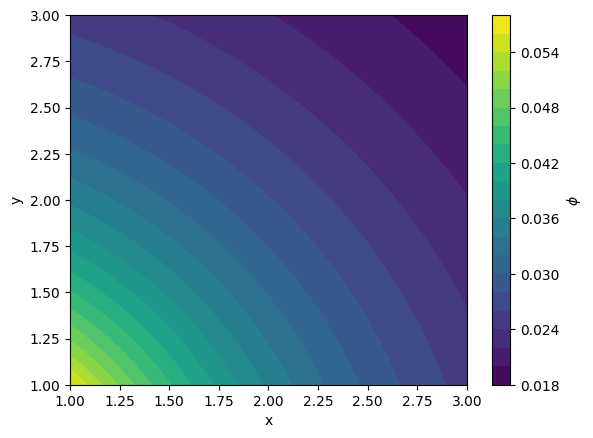

In [7]:


x = x_and_y[:,0]
y = x_and_y[:,1]

plt.figure()
plt.tricontourf(x, y, phi, levels=20)
plt.colorbar(label=r'$\phi$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [8]:


phi_analytical = calc_Phi(x,y,0.)

err_phi = phi - phi_analytical



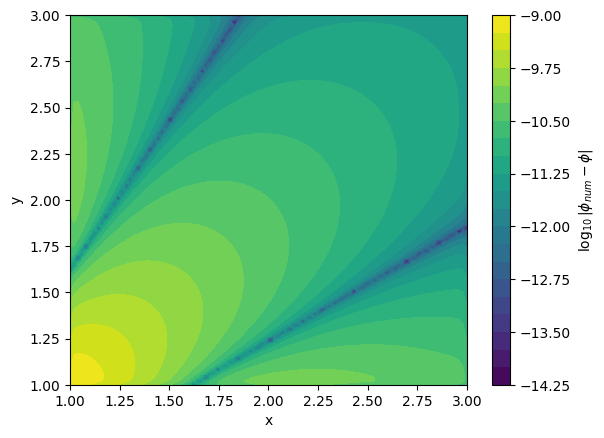

In [9]:
plt.figure()
plt.tricontourf(x, y, np.log10(np.abs(err_phi)), levels=20)
plt.colorbar(label=r'$\log_{10}|\phi_{num} - \phi|$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## Calculate Electric Field 

In [10]:
def calc_electric_field(x_and_y, phi):

    Ex = np.zeros(N**2)
    Ey = np.zeros(N**2)

    x = x_and_y[:,0]
    y = x_and_y[:,1]

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
    
            #calculate indx
            indx = indx+1

            #then check each derivative individually
            if 1<=indx<=N: #do forward derivative
                Ex[indx-1] =  - (-3*phi[indx-1] + 4*phi[indx-1+N] - phi[indx-1+2*N])/(2*h)   #- (phi[indx-1 +N] -  calc_Phi(x[indx-1] - h,y[indx-1],0.))/(2*h)
            elif N**2 - N + 1<=indx<=N**2: #do backward derivative
                Ex[indx-1] =  - (3*phi[indx-1]- 4*phi[indx-1-N] + phi[indx-1-2*N])/(2*h) #- (calc_Phi(x[indx-1] + h,y[indx-1],0.) - phi[indx-1-N] )/(2*h) 
            else:
                Ex[indx-1] = - (phi[indx-1 +N] -  phi[indx-1 -N])/(2*h)

           

            if (indx-1)%N == 0: #forward derivative
                Ey[indx-1] =   - (-3*phi[indx-1] + 4*phi[indx-1+1] - phi[indx-1+2])/(2*h) #- (phi[indx-1+1] -  calc_Phi(x[indx-1],y[indx-1] - h,0.))/(2*h)
            elif indx%N == 0: #backward derivative
                Ey[indx-1] =  - (3*phi[indx-1]- 4*phi[indx-1-1] + phi[indx-1-2])/(2*h)  #- (calc_Phi(x[indx-1],y[indx-1] + h,0.) -  phi[indx-1-1])/(2*h)
            else:
                Ey[indx-1] = - (phi[indx-1+1] -  phi[indx-1-1])/(2*h)
            
          
    
    return Ex, Ey




In [11]:
Ex, Ey = calc_electric_field(x_and_y, phi)

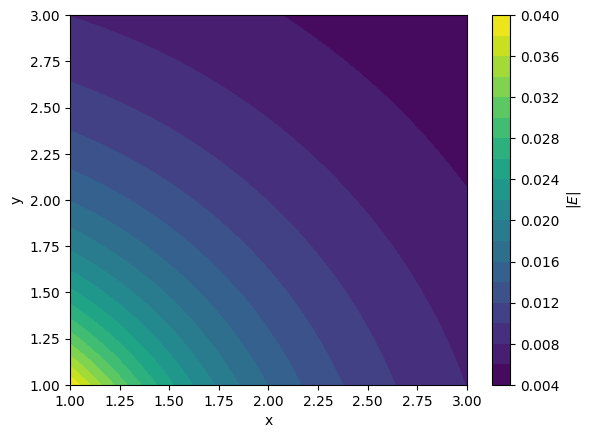

In [12]:
plt.figure()
plt.tricontourf(x, y, np.sqrt(Ex**2 + Ey**2), levels=20)
plt.colorbar(label=r'$|E|$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

In [13]:
E_analytical = calc_E(x,y,0.)

E_err =  np.sqrt(Ex**2. + Ey**2)- E_analytical #these should agree, since at z = 0, Ez = 0 (plane of symmetry)

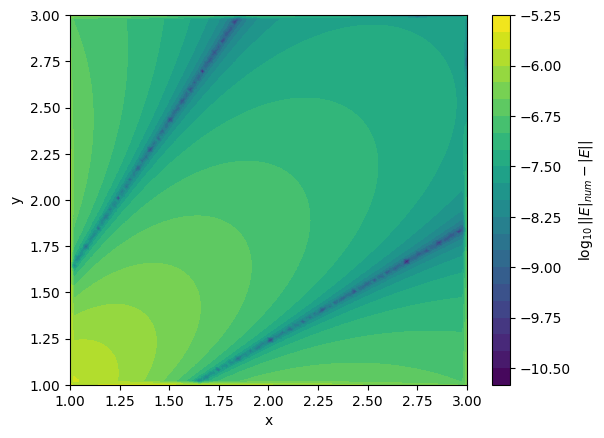

In [14]:
plt.figure()
plt.tricontourf(x, y, np.log10(np.abs(E_err)), levels=20)
plt.colorbar(label=r'$\log_{10}| |E|_{num} - |E||$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## Check that z-Component of Curl Vanishes

In [18]:
def calc_curl_z(x_and_y, Ex, Ey):

    Ey_x = np.zeros(N**2)
    Ex_y = np.zeros(N**2)
    

    x = x_and_y[:,0]
    y = x_and_y[:,1]

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
    
            #calculate indx
            indx = indx+1

            #then check each derivative individually
            if 1<=indx<=N: #do forward derivative
                Ey_x[indx-1] =   (-3*Ey[indx-1] + 4*Ey[indx-1+N] - Ey[indx-1+2*N])/(2*h)  
            elif N**2 - N + 1<=indx<=N**2: #do backward derivative
                Ey_x[indx-1] =   (3*Ey[indx-1]- 4*Ey[indx-1-N] + Ey[indx-1-2*N])/(2*h) 
            else:
                Ey_x[indx-1] =  (Ey[indx-1 +N] -  Ey[indx-1 -N])/(2*h)

           

            if (indx-1)%N == 0: #forward derivative
                Ex_y[indx-1] =    (-3*Ex[indx-1] + 4*Ex[indx-1+1] - Ex[indx-1+2])/(2*h) 
            elif indx%N == 0: #backward derivative
                Ex_y[indx-1] =   (3*Ex[indx-1]- 4*Ex[indx-1-1] + Ex[indx-1-2])/(2*h) 
            else:
                Ex_y[indx-1] =  (Ex[indx-1+1] -  Ex[indx-1-1])/(2*h)
            
          
    
    return Ey_x - Ex_y


In [19]:
curl_E_z = calc_curl_z(x_and_y, Ex, Ey)

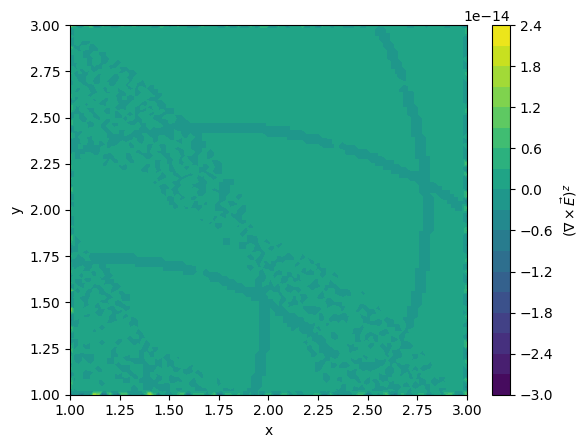

In [20]:
plt.figure()
plt.tricontourf(x, y, curl_E_z, levels=20)
plt.colorbar(label=r'$ (\nabla \times \vec{E})^z$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

## Solve for Potential With Jacobi Iteration

In [26]:
def solve_poisson_jacobi(iter, phi0):

    #we know that the diagonal will be -6 everywhere

    L = -6*np.eye(N**2)

    R = np.zeros(N**2)

    x_and_y = []

    #loop through stencil
    indx = 0
    for i in range(1,N+1):
        for j in range(1,N+1):
            
            #calculate x and y
            x = xmin + (i-1)*h
            y = ymin + (j-1)*h
            x_and_y.append([x,y])

            #calculate indx
            indx = indx+1

            #always add expected source terms
            R[indx-1] = -calc_Phi(x,y,zmin) - calc_Phi(x,y,zmax)

            #then check each term individually
            if 1<=indx<=N:
                R[indx-1] = R[indx-1] - calc_Phi(x - h,y,0.)
            else:
                L[indx-1, indx-1 -N] = 1.

            if N**2 - N + 1<=indx<=N**2:
                R[indx-1] = R[indx-1] - calc_Phi(x + h ,y,0.)
            else:
                L[indx-1, indx-1+N] = 1.

            if (indx-1)%N == 0:
                R[indx-1] = R[indx-1] - calc_Phi(x, y-h, 0.)
            else:
                L[indx-1,indx-1-1] = 1.
            
            if indx%N == 0:
                R[indx-1] = R[indx-1] - calc_Phi(x, y+h, 0.)
            else:
                L[indx-1,indx-1+1] = 1.

    phi = phi0
    D = np.diag(np.diag(L))
    C = L - D    
    residual = np.zeros(iter)
    for i in range(0, iter): 
        phi = (R - C@phi)/(-6)
        residual[i] = np.linalg.norm(L@phi - R)

    return np.array(x_and_y), phi, residual

In [28]:
x_and_y, phi_jacobi, residual_jacobi = solve_poisson_jacobi(50, np.ones(N**2))

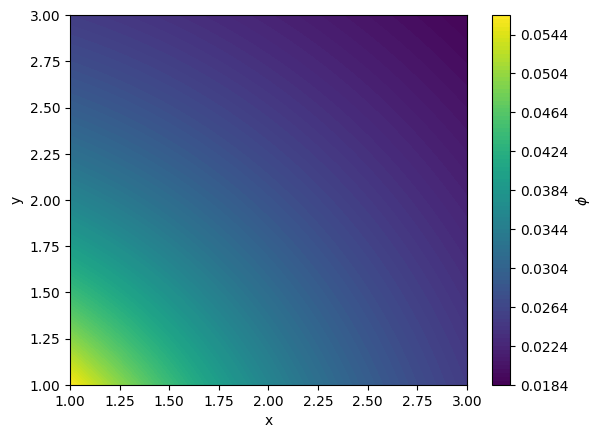

In [29]:
x = x_and_y[:,0]
y = x_and_y[:,1]

plt.figure()
plt.tricontourf(x, y, phi_jacobi, levels=100)
plt.colorbar(label=r'$\phi$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

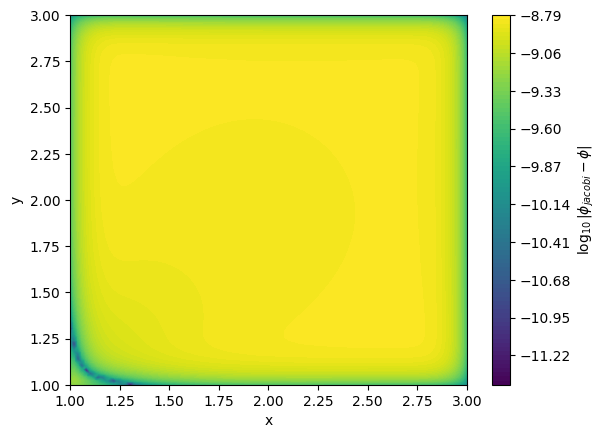

In [30]:
plt.figure()
plt.tricontourf(x, y, np.log10(np.abs(phi_jacobi - phi_analytical)), levels=100)
plt.colorbar(label=r'$\log_{10}|\phi_{jacobi} - \phi|$')
plt.xlabel('x')
plt.ylabel('y')
plt.show()

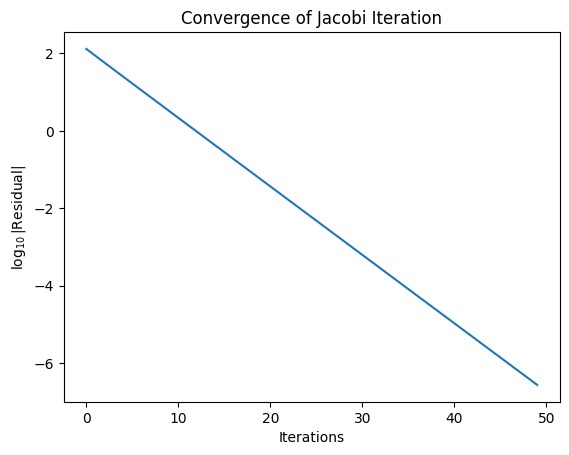

In [33]:
plt.plot(np.log10(np.abs(residual_jacobi)))
plt.title('Convergence of Jacobi Iteration')
plt.xlabel('Iterations')
plt.ylabel(r'$\log_{10}|\text{Residual}|$')
plt.show()